# # 02 · Encoder-only Transformer (BERT)
#
# Same Transformer block as GPT but **no causal mask**: every token sees the whole sequence (left *and* right context).
# It cannot generate text left-to-right, so it is trained with **masked language modelling (MLM)**: hide ~15–25 % of
# tokens and predict them from context. Great for embeddings, classification, retrieval (BERT, RoBERTa, DeBERTa).

In [1]:
import torch, torch.nn as nn, torch.nn.functional as F, matplotlib.pyplot as plt, numpy as np
from llmarch import *
from llmarch.blocks import *
set_seed(0); device = get_device(); STEPS = 1200
data = load_text_data("char"); train, val, V = data["train"], data["val"], data["vocab_size"]
MASK = V                                  # extra [MASK] token id

# ## Causal (GPT) vs bidirectional (BERT) visibility

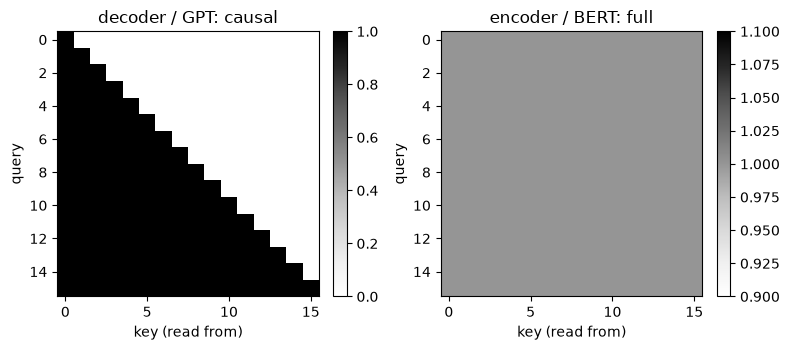

In [2]:
T = 16
fig, ax = plt.subplots(1, 2, figsize=(8, 3.6))
for a, (name, m) in zip(ax, [("decoder / GPT: causal", torch.tril(torch.ones(T, T))), ("encoder / BERT: full", torch.ones(T, T))]):
    plot_heatmap(m, title=name, ax=a, cmap="Greys"); a.set_xlabel("key (read from)"); a.set_ylabel("query")
plt.tight_layout(); plt.show()

# ## Architecture

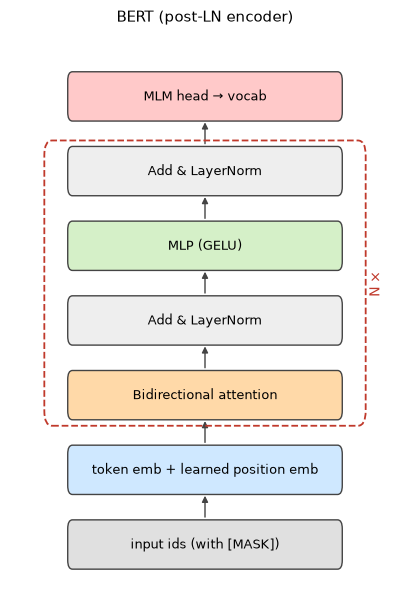

In [3]:
block_diagram([("input ids (with [MASK])", "other"), ("token emb + learned position emb", "embed"), ("Bidirectional attention", "attn*"),
               ("Add & LayerNorm", "norm*"), ("MLP (GELU)", "ffn*"), ("Add & LayerNorm", "norm*"),
               ("MLM head → vocab", "out")], title="BERT (post-LN encoder)", repeat="N ×")

# ## Model: reuse `Block`, but non-causal attention and LayerNorm
# We re-use the library blocks (source shown below) with `causal=False`.

In [4]:
show_source(Attention.mask, Block)

```python
    def mask(self, T, device):
        i = torch.arange(T, device=device)[:, None]; j = torch.arange(T, device=device)[None, :]
        m = (j <= i) if self.causal else torch.ones(T, T, dtype=torch.bool, device=device)
        if self.window is not None:
            m = m & (i - j < self.window) if self.causal else m & ((i - j).abs() < self.window)
        return m

```
```python
class Block(nn.Module):
    """x = x + mixer(norm1(x));  x = x + ffn(norm2(x)).  ffn may return (y, aux) (MoE)."""
    def __init__(self, d, mixer, ffn, norm=RMSNorm):
        super().__init__(); self.n1, self.n2 = norm(d), norm(d); self.mixer, self.ffn = mixer, ffn

    def forward(self, x):
        x = x + self.mixer(self.n1(x))
        y = self.ffn(self.n2(x)); aux = x.new_zeros(())
        if isinstance(y, tuple):
            y, aux = y
        return x + y, aux

```

In [5]:
class BERT(nn.Module):
    def __init__(self, vocab, d=96, n_head=4, n_layer=3, max_T=128):
        super().__init__()
        self.tok, self.pos = nn.Embedding(vocab + 1, d), nn.Embedding(max_T, d)
        self.blocks = nn.ModuleList([Block(d, Attention(d, n_head, causal=False), GELUMLP(d), norm=nn.LayerNorm) for _ in range(n_layer)])
        self.norm = nn.LayerNorm(d); self.head = nn.Linear(d, vocab)
    def forward(self, idx):
        x = self.tok(idx) + self.pos(torch.arange(idx.size(1), device=idx.device))
        for b in self.blocks: x, _ = b(x)
        return self.head(self.norm(x))
model = BERT(V).to(device); print(f"{count_params(model)/1e6:.3f} M params")
_ = show_summary(model, input_data=torch.randint(0, V, (1, 64)), depth=1)

0.361 M params
Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
BERT                                     [1, 64]                   [1, 64, 65]               --
├─Embedding: 1-1                         [1, 64]                   [1, 64, 96]               6,336
├─Embedding: 1-2                         [64]                      [64, 96]                  12,288
├─ModuleList: 1-3                        --                        --                        335,520
├─LayerNorm: 1-4                         [1, 64, 96]               [1, 64, 96]               192
├─Linear: 1-5                            [1, 64, 96]               [1, 64, 65]               6,305
Total params: 360,641
Trainable params: 360,641
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 1.13
Input size (MB): 0.00
Forward/backward pass size (MB): 1.80
Params size (MB): 1.44
Estimated Total Size (MB): 3.25


# ## Masked-LM training
# Loss is computed **only on the masked positions**. (80/10/10 corruption of the original paper is simplified to
# 100 % [MASK] at a 25 % rate, since this is a tiny model.)

step 200 | train 3.191 | val 3.327 | masked-char acc 15.08%


step 400 | train 3.082 | val 3.139 | masked-char acc 17.11%


step 600 | train 2.700 | val 2.804 | masked-char acc 22.25%


step 800 | train 2.477 | val 2.520 | masked-char acc 28.43%


step 1000 | train 2.354 | val 2.384 | masked-char acc 31.54%


step 1200 | train 2.491 | val 2.407 | masked-char acc 30.96%


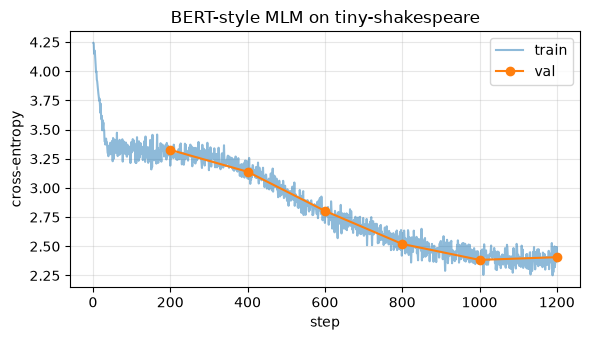

{'params': 360641,
 'val_loss': np.float64(2.4066837072372436),
 'train_loss': 2.396209383010864,
 'note': 'masked-LM loss, not comparable to next-token loss'}

In [6]:
def mlm_batch(data, T=64, B=32, rate=0.25):
    x, _ = get_batch(data, T, B, device)
    m = torch.rand(x.shape, device=device) < rate
    return x.masked_fill(m, MASK), x, m

opt = torch.optim.AdamW(model.parameters(), lr=3e-3, weight_decay=0.01)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=3e-3, total_steps=STEPS, pct_start=.1)
hist = {"step": [], "train": [], "val_step": [], "val": []}
@torch.no_grad()
def mlm_eval(n=20):
    model.eval(); ls = []; acc = []
    for _ in range(n):
        xin, y, m = mlm_batch(val); lg = model(xin)
        ls.append(F.cross_entropy(lg[m], y[m]).item()); acc.append((lg[m].argmax(-1) == y[m]).float().mean().item())
    model.train(); return np.mean(ls), np.mean(acc)
for step in range(1, STEPS + 1):
    xin, y, m = mlm_batch(train); loss = F.cross_entropy(model(xin)[m], y[m])
    opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); sched.step()
    hist["step"].append(step); hist["train"].append(loss.item())
    if step % 200 == 0:
        v, a = mlm_eval(); hist["val_step"].append(step); hist["val"].append(v); print(f"step {step} | train {loss.item():.3f} | val {v:.3f} | masked-char acc {a:.2%}")
plot_losses(hist, "BERT-style MLM on tiny-shakespeare")
save_result("02 BERT (encoder-only, MLM loss)", model, hist, extra={"note": "masked-LM loss, not comparable to next-token loss"})

# ## Fill in the blanks

In [7]:
sent = data["decode"](val[1000:1064].tolist()); ids = val[1000:1064].clone()
g = torch.Generator().manual_seed(1); mask = torch.rand(64, generator=g) < 0.25
inp = ids.masked_fill(mask, MASK)[None].to(device); model.eval()
pred = model(inp)[0].argmax(-1).cpu()
show = lambda t: "".join(data["itos"][i] if i != MASK else "_" for i in t.tolist()).replace("\n", "⏎")
print("original :", show(ids)); print("masked   :", show(inp[0].cpu())); print("predicted:", show(torch.where(mask, pred, ids)))
print(f"correct on masked positions: {(pred[mask]==ids[mask]).float().mean():.0%}")

original : rina, this I know,⏎She is not for your turn, the more my grief.⏎
masked   : rina_ this I know,⏎Sh_ is no_ for__our turn,_t_e m_re my _ri_f.⏎
predicted: rinas this I know,⏎She is not for  our turn, the mere my arinf.⏎
correct on masked positions: 50%


# ## Bidirectional attention maps
# Note the **full matrices**: tokens attend both backwards and forwards (compare with GPT in notebook 01).

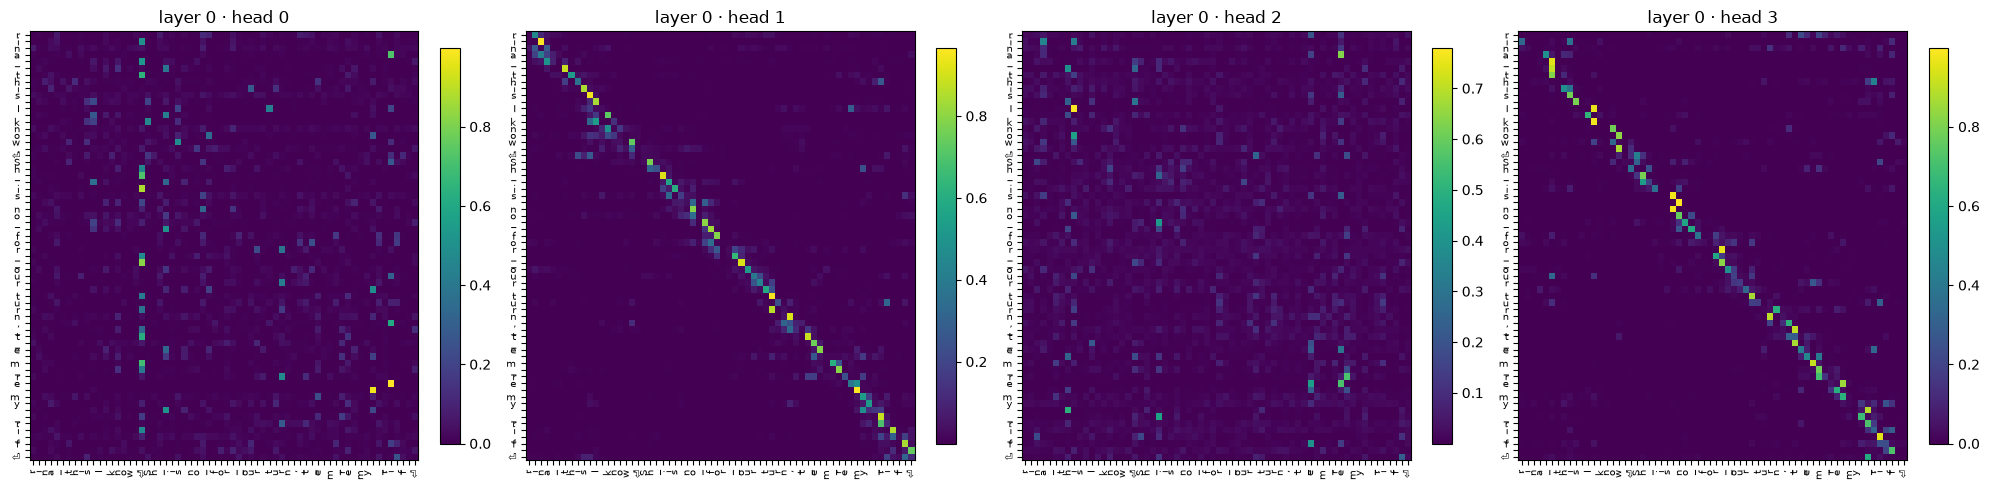

In [8]:
for b in model.blocks: b.mixer.keep_attn = True
model(inp); labels = [data["itos"][i] if i != MASK else "_" for i in inp[0].cpu().tolist()]; labels = [("⏎" if c == "\n" else c) for c in labels]
fig, axs = plt.subplots(1, 4, figsize=(20, 5))
for h, ax in enumerate(axs): plot_heatmap(model.blocks[0].mixer.last_attn[0, h].cpu(), labels, labels, f"layer 0 · head {h}", ax=ax)
plt.tight_layout(); plt.show()

# ## Contextual embeddings (what BERT is *for*)
# The final hidden state of each position is a context-dependent vector. We project those for a few thousand positions
# with PCA and colour by character class — vowels, consonants, space/punct end up in different regions.

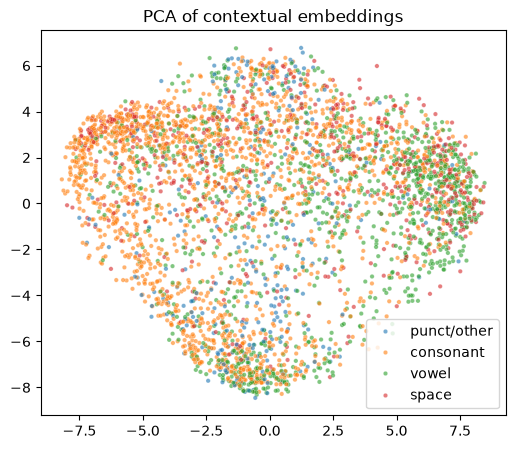

In [9]:
from sklearn.decomposition import PCA
xs = torch.stack([val[i:i+64] for i in range(0, 64*60, 64)]).to(device)
with torch.no_grad():
    h = model.tok(xs) + model.pos(torch.arange(64, device=device))
    for b in model.blocks: h, _ = b(h)
    h = model.norm(h).reshape(-1, h.size(-1)).cpu().numpy()
chars = np.array([data["itos"][i] for i in xs.reshape(-1).cpu().tolist()])
cls = np.where(np.isin(chars, list("aeiouAEIOU")), "vowel", np.where(np.char.isalpha(chars), "consonant", np.where(chars == " ", "space", "punct/other")))
p2 = PCA(2).fit_transform(h)
import seaborn as sns
plt.figure(figsize=(6, 5)); sns.scatterplot(x=p2[:, 0], y=p2[:, 1], hue=cls, s=10, alpha=.6); plt.title("PCA of contextual embeddings"); plt.show()